# Project 07 — 01 — Bootstrap Resampling


## Notebook introduction

- **Concepts required:** Sampling distributions, confidence intervals, autocorrelation in return series.
- **What will be learned:** How to attach honest error bars to Sharpe, Calmar, CAGR and max drawdown using a block / stationary bootstrap.
- **Expected mathematical / statistical background:** Basic probability, percentiles, and the idea of a sampling distribution.
- **Outputs produced:** Bootstrap confidence intervals per metric; `results/bootstrap_intervals.csv`; one evidence record per metric.
- **How this notebook feeds later notebooks:** Provides the block-resampling machinery reused by Monte Carlo (02) and the Reality Check (05); its uncertainty framing motivates the significance tests that follow.


## Purpose

Quantify the sampling uncertainty of the strategy's headline performance metrics using a stationary / circular block bootstrap appropriate for autocorrelated returns, producing confidence intervals rather than point estimates.

> **Scaffold notebook.** Section headings only — no implementation yet. Algorithms live in `src/statistics/bootstrap.py` (currently raising `NotImplementedError`).


## Expected inputs

- Frozen Project 06 baseline strategy returns/equity: `experiments/completed/exp_005_risk_engine_final/final_weighted_multi_strategy_portfolio_dd.csv` (dates from `final_daily_weights.csv`) — the exact series Project 06's golden-master regression validated.
- Run configuration (seed, iteration counts, confidence level)
- Block-length settings for later sensitivity analysis


## Expected outputs

- Confidence intervals for Sharpe, Calmar, CAGR and max drawdown
- Bootstrap distributions per metric
- `results/bootstrap_intervals.csv`
- Evidence-ledger records (one per metric)


## Setup & inputs


This notebook is the **research / analysis layer**. All resampling algorithms live in `src/statistics/bootstrap.py` and are *imported*, never reimplemented here. This first pass loads the frozen Project 06 baseline strategy, validates it, and records the **observed point estimates** of the headline metrics. Those are single-number estimates; later sections quantify their **sampling uncertainty** with the stationary bootstrap.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd

# Locate the repo root by walking up until we find the `src` package, so the
# notebook works regardless of the directory it is launched from.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Tested performance metrics (reused from earlier projects; not reimplemented here).
from src.utils.metrics import (
    sharpe_ratio,
    annualized_return,
    max_drawdown,
    annualized_volatility,
)
# Project 07 bootstrap engine — imported now, used in later sections (no bootstrap this pass).
from src.statistics.bootstrap import bootstrap_metric, bootstrap_confidence_interval

import matplotlib.pyplot as plt
%matplotlib inline
print("repo root:", PROJECT_ROOT)

repo root: /Users/rawls/quant-lab


In [2]:
# --- Load the frozen Project 06 baseline return series -----------------------
# Series chosen because it reproduces the Project 06 golden-master metrics exactly
# (Sharpe 2.0901, CAGR 0.3770, MDD -0.3669, Calmar 1.0274). Dates come from the
# daily-weights export, exactly as Project 06's deployment_reference.py loads them.
EXP_DIR = PROJECT_ROOT / "experiments/completed/exp_005_risk_engine_final"
RETURNS_FILE = EXP_DIR / "final_weighted_multi_strategy_portfolio_dd.csv"
WEIGHTS_FILE = EXP_DIR / "final_daily_weights.csv"
STRATEGY_NAME = (
    "Project 05 final weighted multi-strategy portfolio (DD-overlay) "
    "— frozen Project 06 baseline"
)

ret_df = pd.read_csv(RETURNS_FILE)
weights_long = pd.read_csv(WEIGHTS_FILE, parse_dates=["Date"])
dates = (
    weights_long.pivot(index="Date", columns="Ticker", values="Weight")
    .sort_index()
    .index
)
assert len(dates) == len(ret_df), (len(dates), len(ret_df))

returns = pd.Series(ret_df["portfolio_return"].to_numpy(), index=dates, name="returns")
equity = pd.Series(ret_df["equity_curve"].to_numpy(), index=dates, name="equity")

print("source        :", RETURNS_FILE.relative_to(PROJECT_ROOT))
print("date source   :", WEIGHTS_FILE.relative_to(PROJECT_ROOT))
print("strategy      :", STRATEGY_NAME)
print("observations  :", len(returns))
print("date range    :", returns.index.min().date(), "->", returns.index.max().date())
print("missing returns:", int(returns.isna().sum()), "| missing equity:", int(equity.isna().sum()))

source        : experiments/completed/exp_005_risk_engine_final/final_weighted_multi_strategy_portfolio_dd.csv
date source   : experiments/completed/exp_005_risk_engine_final/final_daily_weights.csv
strategy      : Project 05 final weighted multi-strategy portfolio (DD-overlay) — frozen Project 06 baseline
observations  : 2558
date range    : 2016-01-04 -> 2026-03-06
missing returns: 0 | missing equity: 0


In [3]:
# --- Data validation (fail loudly; never drop observations silently) ---------
n_before = len(returns)
assert n_before > 0, "return series is empty"
assert pd.api.types.is_numeric_dtype(returns), "returns are not numeric"
assert returns.index.is_monotonic_increasing, "dates are not ordered"
assert returns.index.is_unique, "duplicate dates present"
assert np.isfinite(returns.to_numpy()).all(), "returns contain NaN/Inf"
assert np.isfinite(equity.to_numpy()).all(), "equity contains NaN/Inf"

# No cleaning is applied: the frozen artifact is used exactly as validated by
# Project 06. This assertion guards against any accidental silent row drop.
assert len(returns) == n_before, "observation count changed (silent drop)"
print(f"validation passed: {n_before} observations, numeric, ordered, unique, finite; no cleaning applied")

validation passed: 2558 observations, numeric, ordered, unique, finite; no cleaning applied


### Reproducibility parameters

In [4]:
# Fixed, documented configuration so every later result is reproducible.
BOOTSTRAP_SEED = 20260820          # fixed seed (Project 07 start date); do not change casually
N_BOOTSTRAP = 10_000               # bootstrap resamples (used in later sections)
CONFIDENCE_LEVEL = 0.95            # nominal confidence-interval coverage
PERIODS_PER_YEAR = 252             # annualisation factor for Sharpe / CAGR

# Candidate stationary-bootstrap mean block lengths for the later sensitivity
# analysis (single source of truth). ~sqrt(n) heuristic, bracketed for the sweep.
BLOCK_LENGTHS = [5, 10, 20, 30, 50]

print("seed:", BOOTSTRAP_SEED, "| n_bootstrap:", N_BOOTSTRAP,
      "| confidence:", CONFIDENCE_LEVEL, "| block lengths:", BLOCK_LENGTHS)

seed: 20260820 | n_bootstrap: 10000 | confidence: 0.95 | block lengths: [5, 10, 20, 30, 50]


## Observed baseline metrics

Point estimates computed with the **tested** functions from `src/utils/metrics.py` (reused, not rewritten). Calmar is derived as `CAGR / |MDD|`. These are the values whose sampling uncertainty later sections will bootstrap — **no bootstrap is run here**.

In [5]:
# Observed point estimates (source function shown per row).
obs_sharpe = sharpe_ratio(returns, periods_per_year=PERIODS_PER_YEAR)      # src.utils.metrics.sharpe_ratio
obs_cagr = annualized_return(returns, periods_per_year=PERIODS_PER_YEAR)   # src.utils.metrics.annualized_return
obs_mdd = max_drawdown(equity)                                            # src.utils.metrics.max_drawdown
obs_calmar = obs_cagr / abs(obs_mdd)                                       # derived: CAGR / |MDD|

baseline = pd.DataFrame(
    {
        "Metric": ["Sharpe ratio", "CAGR", "Maximum Drawdown", "Calmar ratio"],
        "Observed value": [obs_sharpe, obs_cagr, obs_mdd, obs_calmar],
        "Source": [
            "src.utils.metrics.sharpe_ratio",
            "src.utils.metrics.annualized_return",
            "src.utils.metrics.max_drawdown",
            "CAGR / |MDD| (annualized_return, max_drawdown)",
        ],
    }
)
baseline.round(6)

,Metric,Observed value,Source
0,Sharpe ratio,2.090113,src.utils.metrics.sharpe_ratio
1,CAGR,0.377021,src.utils.metrics.annualized_return
2,Maximum Drawdown,-0.366949,src.utils.metrics.max_drawdown
3,Calmar ratio,1.027446,"CAGR / |MDD| (annualized_return, max_drawdown)"


## Choose bootstrap scheme & block length


**Why not the iid bootstrap.** Resampling single days independently assumes returns are iid. Financial returns are not — volatility clusters and there is short-run autocorrelation. The iid bootstrap destroys that dependence and therefore *understates* the sampling uncertainty of path-dependent metrics (Sharpe, drawdown, Calmar).

**Stationary bootstrap.** Project 07 resamples *random-length contiguous blocks* (Politis–Romano), via `src/statistics/bootstrap.py`, preserving short-range dependence while keeping the resampled series stationary.

**Expected block length.** The mean length of those blocks. Larger values retain more autocorrelation; `expected_block_length = 1` reduces to the iid bootstrap.

**Why a block-length sensitivity analysis later.** The block length is a nuisance parameter, so a single choice could bias the intervals. A later section sweeps `BLOCK_LENGTHS` to confirm the conclusions are not an artifact of one value.

In [6]:
# BOOTSTRAP_SEED and N_BOOTSTRAP were fixed in the Reproducibility parameters cell
# above (single source of truth); this run also fixes the mean block length.
EXPECTED_BLOCK_LENGTH = 20   # one of the BLOCK_LENGTHS candidates; swept later

# One generator, seeded once, drives ALL randomness in this notebook — no ad-hoc
# np.random calls anywhere else.
rng = np.random.default_rng(BOOTSTRAP_SEED)

print("seed:", BOOTSTRAP_SEED, "| n_bootstrap:", N_BOOTSTRAP,
      "| expected_block_length:", EXPECTED_BLOCK_LENGTH)

seed: 20260820 | n_bootstrap: 10000 | expected_block_length: 20


In [7]:
# First bootstrap experiment: Sharpe only (CAGR / MDD / Calmar come in later sections).
# sharpe_ratio coerces its input to a pandas Series internally, so it is consistent
# (ddof=1) whether it receives the observed Series or a bootstrap NumPy resample.
sharpe_dist = bootstrap_metric(
    returns.to_numpy(),
    sharpe_ratio,            # src.utils.metrics.sharpe_ratio
    N_BOOTSTRAP,
    EXPECTED_BLOCK_LENGTH,
    rng,
)
print("Sharpe bootstrap distribution:", sharpe_dist.shape, sharpe_dist.dtype)

Sharpe bootstrap distribution: (10000,) float64


In [8]:
# Bootstrap standard error + percentile confidence interval for the Sharpe ratio.
sharpe_se, sharpe_ci_low, sharpe_ci_high = bootstrap_confidence_interval(
    sharpe_dist, CONFIDENCE_LEVEL
)
print(f"bootstrap standard error : {sharpe_se:.6f}")
print(f"{int(CONFIDENCE_LEVEL * 100)}% confidence interval : "
      f"[{sharpe_ci_low:.6f}, {sharpe_ci_high:.6f}]")

bootstrap standard error : 0.588630
95% confidence interval : [0.910705, 3.228796]


In [9]:
# --- Sanity checks ---
print("n bootstrap samples :", sharpe_dist.size)
print("distribution mean   :", float(np.mean(sharpe_dist)))
print("distribution std    :", float(np.std(sharpe_dist, ddof=1)))
print("observed Sharpe     :", obs_sharpe)

assert sharpe_dist.size == N_BOOTSTRAP, "distribution length != N_BOOTSTRAP"
assert np.isfinite(sharpe_dist).all(), "distribution contains NaN/Inf"
print("checks passed: length == N_BOOTSTRAP and no NaN/Inf")

n bootstrap samples : 10000
distribution mean   : 2.0891793705803043
distribution std    : 0.5886301364488551
observed Sharpe     : 2.0901126366076075
checks passed: length == N_BOOTSTRAP and no NaN/Inf


## Sharpe ratio confidence interval


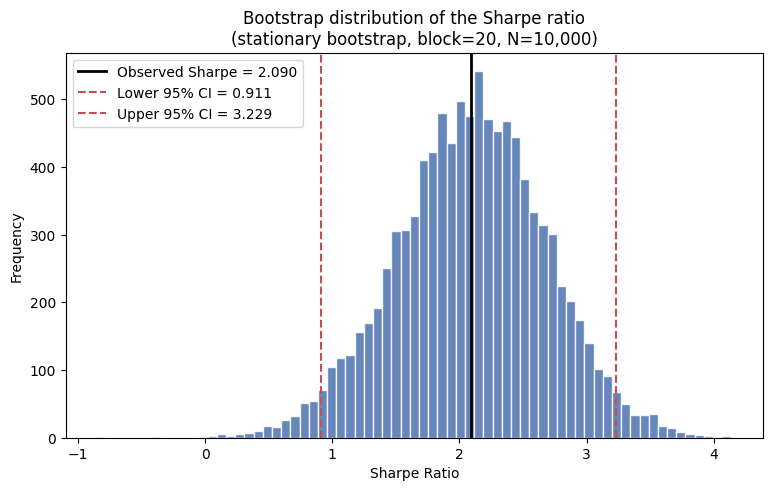

In [10]:
# Visualise the ALREADY-computed Sharpe bootstrap distribution (no re-bootstrapping).
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(sharpe_dist, bins="auto", color="#4C72B0", alpha=0.85, edgecolor="white")
ax.axvline(obs_sharpe, color="black", linewidth=2,
           label=f"Observed Sharpe = {obs_sharpe:.3f}")
ax.axvline(sharpe_ci_low, color="#C44E52", linestyle="--", linewidth=1.5,
           label=f"Lower 95% CI = {sharpe_ci_low:.3f}")
ax.axvline(sharpe_ci_high, color="#C44E52", linestyle="--", linewidth=1.5,
           label=f"Upper 95% CI = {sharpe_ci_high:.3f}")
ax.set_title("Bootstrap distribution of the Sharpe ratio\n"
             "(stationary bootstrap, block=20, N=10,000)")
ax.set_xlabel("Sharpe Ratio")
ax.set_ylabel("Frequency")
ax.legend()
plt.show()

In [11]:
# Descriptive summary of the bootstrap Sharpe distribution.
# Skewness via pandas .skew() (Fisher-Pearson, bias-corrected) — no new dependency.
sharpe_series = pd.Series(sharpe_dist)
sharpe_summary = pd.Series(
    {
        "mean": sharpe_series.mean(),
        "median": sharpe_series.median(),
        "std": sharpe_series.std(),      # ddof=1
        "min": sharpe_series.min(),
        "max": sharpe_series.max(),
        "skewness": sharpe_series.skew(),
    }
)
sharpe_summary.round(6).to_frame("Bootstrap Sharpe distribution")

,Bootstrap Sharpe distribution
mean,2.089179
median,2.102625
std,0.588630
min,-0.846096
max,4.137495
skewness,-0.094441


**Interpretation (descriptive).** The bootstrap Sharpe distribution is **approximately symmetric**: skewness ≈ −0.09 (near zero) and the mean (≈2.089) and median (≈2.103) nearly coincide. The **observed Sharpe (≈2.090) lies essentially at the centre**, as expected for an unbiased resampling estimate. The distribution is **unimodal** — a single dominant peak, with no evidence of multiple modes. There is a mild left tail (minimum ≈ −0.85 across resamples) but no extreme isolated outliers; the salient feature is simply the **wide spread** (std ≈ 0.59), consistent with the broad 95% interval [0.91, 3.23]. No stronger claims are drawn from one figure.

## Calmar & max-drawdown intervals


Bootstrap the remaining headline metrics on the **same return series and configuration** (`N_BOOTSTRAP`, `EXPECTED_BLOCK_LENGTH`, and the seeded `rng`). These metrics are path-dependent, so each resample rebuilds **its own** equity curve — Calmar and max-drawdown are computed from the resampled path, not the original equity. The Sharpe results above are reused, not recomputed.

In [12]:
# Path-dependent metric wrappers. bootstrap_metric passes a RESAMPLED return array,
# so drawdown-based metrics must rebuild the equity curve from that resample.
def cagr_fn(r):
    return annualized_return(r)                              # src.utils.metrics.annualized_return

def mdd_fn(r):
    return max_drawdown((1 + pd.Series(r)).cumprod())        # equity rebuilt from resample

def calmar_fn(r):
    m = max_drawdown((1 + pd.Series(r)).cumprod())
    return annualized_return(r) / abs(m) if m != 0 else np.nan   # CAGR / |MDD|

In [13]:
# Reuse the same generator (its stream continues after the Sharpe run above) and the
# same N_BOOTSTRAP / EXPECTED_BLOCK_LENGTH. Sharpe is NOT re-bootstrapped here.
returns_np = returns.to_numpy()
cagr_dist = bootstrap_metric(returns_np, cagr_fn, N_BOOTSTRAP, EXPECTED_BLOCK_LENGTH, rng)
mdd_dist = bootstrap_metric(returns_np, mdd_fn, N_BOOTSTRAP, EXPECTED_BLOCK_LENGTH, rng)
calmar_dist = bootstrap_metric(returns_np, calmar_fn, N_BOOTSTRAP, EXPECTED_BLOCK_LENGTH, rng)

for _name, _d in [("CAGR", cagr_dist), ("MDD", mdd_dist), ("Calmar", calmar_dist)]:
    assert _d.size == N_BOOTSTRAP and np.isfinite(_d).all(), f"{_name} distribution invalid"
print("bootstrapped (size each):",
      {"CAGR": cagr_dist.size, "MDD": mdd_dist.size, "Calmar": calmar_dist.size})

bootstrapped (size each): {'CAGR': 10000, 'MDD': 10000, 'Calmar': 10000}


In [14]:
# Compact interval summary for CAGR, max-drawdown and Calmar.
def _interval_row(name, observed, dist):
    se, lo, hi = bootstrap_confidence_interval(dist, CONFIDENCE_LEVEL)
    return {
        "Metric": name,
        "Observed": observed,
        "Bootstrap Mean": float(dist.mean()),
        "Standard Error": se,
        "95% CI Lower": lo,
        "95% CI Upper": hi,
    }

interval_table = pd.DataFrame(
    [
        _interval_row("CAGR", obs_cagr, cagr_dist),
        _interval_row("Maximum Drawdown", obs_mdd, mdd_dist),
        _interval_row("Calmar ratio", obs_calmar, calmar_dist),
    ]
)
interval_table.round(6)

,Metric,Observed,Bootstrap Mean,Standard Error,95% CI Lower,95% CI Upper
0,CAGR,0.377021,0.384065,0.143821,0.136134,0.699676
1,Maximum Drawdown,-0.366949,-0.363306,0.087250,-0.570487,-0.227728
2,Calmar ratio,1.027446,1.159266,0.614315,0.279356,2.661858


**Interpretation (descriptive).** Sampling uncertainty differs markedly across the metrics. **Max drawdown** is comparatively the tightest (SE ≈ 0.09 on an observed ≈ −0.37) and its interval stays firmly negative. **CAGR** carries wider *relative* uncertainty (SE ≈ 0.14 on ≈ 0.38; CI ≈ [0.14, 0.70]). **Calmar** is the widest and clearly **right-skewed** — its bootstrap mean (≈ 1.16) exceeds the observed value (≈ 1.03) and its CI ≈ [0.28, 2.66] is broad, as expected for a ratio bounded near zero below with a long upper tail. These are single-strategy sampling-uncertainty statements only — no strategy comparison is drawn here.

## CAGR interval

*CAGR is bootstrapped together with max-drawdown and Calmar in the section above; see the combined interval table there.*

## Sensitivity to block length


Vary **only** the mean block length and re-bootstrap the **Sharpe ratio**, holding the return series, `N_BOOTSTRAP`, and seed fixed. A **fresh generator seeded with `BOOTSTRAP_SEED`** is used for each block length, so the runs are deterministic and directly comparable — only the block length changes. (The block=20 row therefore reproduces the Sharpe result computed earlier.)

In [15]:
# Block-length sensitivity — Sharpe only. Fresh, identically-seeded RNG per block
# length so the experiments differ only in the block-length parameter.
# Uses the single BLOCK_LENGTHS list defined in the Reproducibility cell.
rows = []
for bl in BLOCK_LENGTHS:
    rng_bl = np.random.default_rng(BOOTSTRAP_SEED)
    dist = bootstrap_metric(returns_np, sharpe_ratio, N_BOOTSTRAP, bl, rng_bl)
    se, lo, hi = bootstrap_confidence_interval(dist, CONFIDENCE_LEVEL)
    rows.append(
        {
            "Expected Block Length": bl,
            "Bootstrap Mean": float(dist.mean()),
            "Standard Error": se,
            "CI Lower": lo,
            "CI Upper": hi,
        }
    )

sensitivity_table = pd.DataFrame(rows)
sensitivity_table.round(6)

,Expected Block Length,Bootstrap Mean,Standard Error,CI Lower,CI Upper
0,5,2.082358,0.514709,1.055113,3.056844
1,10,2.078636,0.563474,0.968245,3.171323
2,20,2.089179,0.588630,0.910705,3.228796
3,30,2.077555,0.584501,0.921606,3.194006
4,50,2.080928,0.598428,0.881936,3.208234


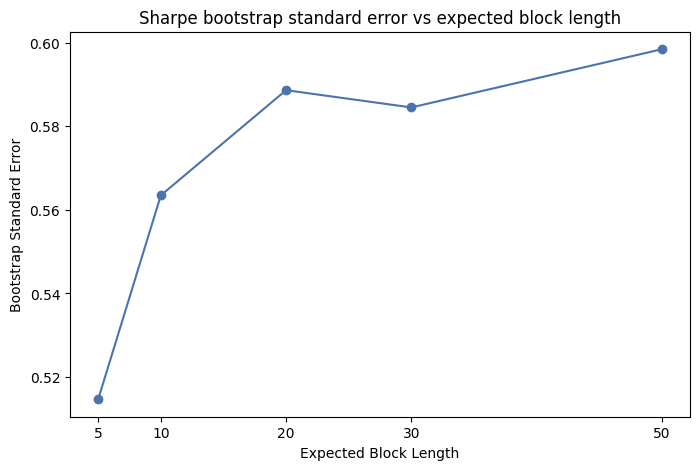

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sensitivity_table["Expected Block Length"], sensitivity_table["Standard Error"],
        marker="o", color="#4C72B0")
ax.set_title("Sharpe bootstrap standard error vs expected block length")
ax.set_xlabel("Expected Block Length")
ax.set_ylabel("Bootstrap Standard Error")
ax.set_xticks(sensitivity_table["Expected Block Length"])
plt.show()

**Interpretation (descriptive).** The bootstrap **mean is stable** across block lengths (≈ 2.08–2.09, all near the observed 2.090). The **standard error rises with block length** — ≈ 0.51 (5) → 0.59 (20) → 0.60 (50) — the expected pattern: short blocks behave more like the iid bootstrap and understate serial dependence, so the estimated uncertainty grows as blocks lengthen, then roughly **plateaus for block lengths ≥ ~20**. The 95% intervals stay broadly similar (lower bound ≈ 0.9–1.1, upper ≈ 3.1–3.2), so no block length in this range overturns the qualitative conclusion. The uncertainty estimates are therefore **not an artifact of a single block-length choice**; block=20 is a reasonable central value. No stronger claims are drawn.

## Results table


In [17]:
# Consolidated final results — reuses the already-computed distributions and the
# Sharpe scalars; no bootstrap is regenerated here.
sharpe_row = pd.DataFrame([{
    "Metric": "Sharpe ratio",
    "Observed Estimate": obs_sharpe,
    "Bootstrap Mean": float(sharpe_dist.mean()),
    "Bootstrap Standard Error": sharpe_se,
    "95% CI Lower": sharpe_ci_low,
    "95% CI Upper": sharpe_ci_high,
}])
others = interval_table.rename(columns={
    "Observed": "Observed Estimate",
    "Standard Error": "Bootstrap Standard Error",
})[["Metric", "Observed Estimate", "Bootstrap Mean",
    "Bootstrap Standard Error", "95% CI Lower", "95% CI Upper"]]

final_results = pd.concat([sharpe_row, others], ignore_index=True)
final_results.round(6)

,Metric,Observed Estimate,Bootstrap Mean,Bootstrap Standard Error,95% CI Lower,95% CI Upper
0,Sharpe ratio,2.090113,2.089179,0.588630,0.910705,3.228796
1,CAGR,0.377021,0.384065,0.143821,0.136134,0.699676
2,Maximum Drawdown,-0.366949,-0.363306,0.087250,-0.570487,-0.227728
3,Calmar ratio,1.027446,1.159266,0.614315,0.279356,2.661858


### Block-length robustness (Sharpe)

Reusing the sensitivity study above (expected block lengths **5, 10, 20, 30, 50**):

| Block length | Sharpe SE | 95% CI |
| --- | --- | --- |
| 5  | 0.515 | [1.06, 3.06] |
| 10 | 0.563 | [0.97, 3.17] |
| 20 | 0.589 | [0.91, 3.23] |
| 30 | 0.585 | [0.92, 3.19] |
| 50 | 0.598 | [0.88, 3.21] |

**Does the research conclusion change materially? No.** There is genuine *numerical* movement — the standard error rises from ≈0.51 (block 5) to ≈0.60 (block 50) as longer blocks retain more serial dependence, and the CI bounds shift by a few hundredths. But the *scientific* conclusion is unchanged across the whole range: the Sharpe point estimate stays ≈2.08–2.09, the sampling uncertainty is large, and the lower 95% bound stays comfortably above zero (≈0.88–1.06). The numerical movement in SE/CI is not a change in conclusion.

## Evidence ledger

Record every conclusion produced above as an `EvidenceRecord` (`src/statistics/evidence.py`): strategy version, Project 06 freeze tag, dataset, date range, parameters, seed, method, assumptions, statistic, p-value / interval, decision, limitations, timestamp.


In [18]:
from datetime import datetime, timezone
from src.statistics.evidence import (
    EvidenceRecord, EvidenceLedger, Decision, StatisticalMethod,
)

# Build the Notebook 01 bootstrap evidence against the EXISTING canonical schema.
record = EvidenceRecord(
    record_id="p07_nb01_bootstrap_stationary_stat_v1",
    strategy_version=STRATEGY_NAME,
    project06_freeze_tag="project-06-deployment-validation-frozen",
    experiment_id="exp_005_risk_engine_final",
    dataset=str(RETURNS_FILE.relative_to(PROJECT_ROOT)),
    date_range=(str(returns.index.min().date()), str(returns.index.max().date())),
    parameters={
        "bootstrap_method": "stationary",
        "n_bootstrap": N_BOOTSTRAP,
        "baseline_expected_block_length": EXPECTED_BLOCK_LENGTH,
        "tested_block_lengths": BLOCK_LENGTHS,
        "confidence_level": CONFIDENCE_LEVEL,
        "periods_per_year": PERIODS_PER_YEAR,
        "ci_method": "percentile",
    },
    random_seed=BOOTSTRAP_SEED,
    notebook="research/project_07_statistical_integrity/notebooks/01_bootstrap.ipynb",
    source_module="src/statistics/bootstrap.py",
    method=StatisticalMethod.BOOTSTRAP,
    method_version="stat_v1",
    assumptions=(
        "Stationary bootstrap (Politis-Romano); approximate stationarity of returns; "
        "random-length blocks preserve local serial dependence; historical sample assumed "
        "representative; fixed seed; N=10000 resamples; percentile CIs."
    ),
    hypothesis=(
        "Quantify the sampling uncertainty (standard error and 95% CI) of the strategy's "
        "headline performance metrics (Sharpe, CAGR, MDD, Calmar)."
    ),
    test_statistic=float(obs_sharpe),                       # headline observed Sharpe
    confidence_interval=(float(sharpe_ci_low), float(sharpe_ci_high)),
    confidence_level=CONFIDENCE_LEVEL,
    bootstrap_iterations=N_BOOTSTRAP,
    paper_reference="Politis & Romano (1994), The Stationary Bootstrap",
    research_reference="Project 07 — Notebook 01 (Bootstrap)",
    implementation_version="stat_v1",
    decision=Decision.INCONCLUSIVE,   # uncertainty quantified; genuineness of alpha NOT established
    limitations=(
        "Stationary bootstrap may fragment long regimes; depends on sample representativeness; "
        "cannot generate unseen market structures; regime-specific integrity not yet tested."
    ),
    timestamp=datetime.now(timezone.utc),
    extra={
        "observed_metrics": {
            "sharpe": float(obs_sharpe), "cagr": float(obs_cagr),
            "mdd": float(obs_mdd), "calmar": float(obs_calmar),
        },
        "bootstrap_results": final_results.round(6).to_dict("records"),
        "block_length_sensitivity": sensitivity_table.round(6).to_dict("records"),
        "qualitative_robustness": (
            "Sharpe SE/CI move numerically with block length (SE 0.51->0.60 over blocks 5->50) "
            "but the conclusion is stable: Sharpe ~2.09 with wide uncertainty and a lower 95% "
            "bound comfortably above 0 across all tested block lengths."
        ),
        "status": "bootstrap evidence completed",
    },
)

# Persistence (EvidenceLedger.append) is a later milestone (P07-6); it is not implemented
# yet, so the record is constructed against the schema and displayed for review.
ledger = EvidenceLedger()
try:
    ledger.append(record)
    print("Record appended to the Evidence Ledger.")
except NotImplementedError:
    print("Evidence Ledger persistence not implemented yet (Project 07 milestone P07-6);")
    print("record constructed against the canonical schema and displayed below (not persisted).")

Evidence Ledger persistence not implemented yet (Project 07 milestone P07-6);
record constructed against the canonical schema and displayed below (not persisted).


In [19]:
# Render the exact record for review.
import dataclasses, pprint
_rec = dataclasses.asdict(record)
_rec["method"] = record.method.value
_rec["decision"] = record.decision.value
_rec["timestamp"] = record.timestamp.isoformat()
pprint.pp(_rec, sort_dicts=False, width=100)

{'record_id': 'p07_nb01_bootstrap_stationary_stat_v1',
 'strategy_version': 'Project 05 final weighted multi-strategy portfolio (DD-overlay) — frozen '
                     'Project 06 baseline',
 'project06_freeze_tag': 'project-06-deployment-validation-frozen',
 'experiment_id': 'exp_005_risk_engine_final',
 'dataset': 'experiments/completed/exp_005_risk_engine_final/final_weighted_multi_strategy_portfolio_dd.csv',
 'date_range': ('2016-01-04', '2026-03-06'),
 'parameters': {'bootstrap_method': 'stationary',
                'n_bootstrap': 10000,
                'baseline_expected_block_length': 20,
                'tested_block_lengths': [5, 10, 20, 30, 50],
                'confidence_level': 0.95,
                'periods_per_year': 252,
                'ci_method': 'percentile'},
 'random_seed': 20260820,
 'notebook': 'research/project_07_statistical_integrity/notebooks/01_bootstrap.ipynb',
 'source_module': 'src/statistics/bootstrap.py',
 'method': 'bootstrap',
 'method_version':

## Conclusions

### Statistical interpretation (bootstrap evidence)

- The **observed Sharpe remains ≈ 2.09** on the frozen Project 06 baseline series.
- The **stationary bootstrap reveals meaningful sampling uncertainty**: the 95% Sharpe interval is wide (≈ [0.91, 3.23] at block 20), i.e. a single point estimate materially overstates precision.
- The **observed Sharpe sits close to the centre** of its bootstrap distribution (bootstrap mean ≈ 2.089 vs observed ≈ 2.090), consistent with an approximately unbiased estimate.
- The **Sharpe bootstrap distribution is approximately symmetric and unimodal** (skewness ≈ −0.09, single peak) based on the histogram analysis above.
- **Block-length sensitivity is reasonably stable** across 5–50: SE/CI move numerically but the conclusion does not.
- **CAGR and maximum drawdown also carry meaningful uncertainty** (CAGR CI ≈ [0.14, 0.70]; MDD CI ≈ [−0.57, −0.23]).
- **Calmar exhibits particularly substantial uncertainty** and is right-skewed (CI ≈ [0.28, 2.66]; bootstrap mean > observed).

**Scope of this evidence.** The bootstrap **quantifies estimator uncertainty** around the observed metrics; it does **not** establish that the alpha is genuine, and it is **not a direct forecast of future performance**. Whether the edge is statistically real — accounting for selection, multiple testing, and data-snooping — is addressed by the later Project 07 notebooks. No deployment judgement is made here.

### Limitations

- The **stationary bootstrap preserves local dependence** (via random-length blocks) but can **fragment long economic events / regimes** that span more than a typical block.
- Results **depend on the historical sample being reasonably representative** of the return-generating process.
- The bootstrap **cannot generate entirely unseen market structures** — it recombines observed returns and cannot invent regimes absent from the sample.
- **Regime-specific statistical integrity has not yet been tested** (uncertainty here is pooled across the whole sample).
- **Future work** may investigate **adaptive / regime-aware resampling**; it is *not* implemented here.

### Notebook status

**Notebook 01 (Bootstrap) — COMPLETE.** Deliverables produced: observed baseline metrics, stationary-bootstrap distributions and 95% intervals for Sharpe / CAGR / MDD / Calmar, block-length sensitivity, and an Evidence Ledger record (`status: bootstrap evidence completed`).

Not started here (later Project 07 notebooks): permutation tests, Monte Carlo, Deflated Sharpe, multiple-testing corrections, White's Reality Check / SPA.